# MsPacman-v5: Deep Q-Network (Assignment 2b)

Nature-style DQN on 4 stacked frames, gamma = 0.99, one GPU.

- `RUN_TRAINING = True`: train. A checkpoint is saved every 25 episodes and training resumes automatically; an empty file named `STOP` in the run folder stops it cleanly.
- `RUN_TRAINING = False`: load the saved run and make the plots, the evaluation and the tests.

In [ ]:
import importlib.util, subprocess, sys

def ensure(module, pip_spec):
    if importlib.util.find_spec(module) is None:
        print("installing", pip_spec)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_spec], check=True)

ensure("gymnasium", "gymnasium[atari]>=1.1")
ensure("ale_py", "ale-py>=0.10")
ensure("torch", "torch")

## Imports and device

In [2]:
import os
GPU_INDEX = "0"                                    # single GPU
os.environ.setdefault("CUDA_VISIBLE_DEVICES", GPU_INDEX)

import time, json, copy
from collections import deque
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import clear_output
import gymnasium as gym
import ale_py

gym.register_envs(ale_py)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.enabled = False 
print(f"gymnasium {gym.__version__} | ale-py {ale_py.__version__} | torch {torch.__version__}")
print(f"device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "  <- no GPU visible: training would take days"))

C_BLUE, C_ORANGE, C_AQUA, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110})

gymnasium 1.4.0 | ale-py 0.12.1 | torch 2.14.0+cu126
device: cuda (NVIDIA GeForce GTX 1080)


## Output folder

In [3]:
SAVE_ROOT = "./rl_hw2_mspacman"
RUN_NAME = "dqn_v1"
RUN_DIR = os.path.join(SAVE_ROOT, RUN_NAME)
os.makedirs(RUN_DIR, exist_ok=True)
CKPT_PATH = os.path.join(RUN_DIR, "checkpoint.pt")
BEST_PATH = os.path.join(RUN_DIR, "best.pt")
HIST_PATH = os.path.join(RUN_DIR, "history.json")
BUFFER_PATH = os.path.join(RUN_DIR, "replay_buffer.npz")
HELDOUT_PATH = os.path.join(RUN_DIR, "heldout_states.npy")
LOG_PATH = os.path.join(RUN_DIR, "log.txt")
STOP_PATH = os.path.join(RUN_DIR, "STOP")
print("Run folder:", os.path.abspath(RUN_DIR))

Run folder: /nfs/home/kij6504/rl_hw2_mspacman/dqn_v1


## Settings

Rewards are clipped to sign(r) for learning (scores are reported unclipped). A lost life is terminal for the target only.

In [4]:
GAMMA = 0.99
FRAME_STACK = 4
H, W = 88, 80
N_ACTIONS = 9
BUFFER_SIZE = 200_000
BATCH_SIZE = 32
WARMUP_STEPS = 20_000
TRAIN_EVERY = 4
TARGET_SYNC = 4_000
LR, LR_FLOOR = 1e-4, 0.25
USE_LR_SCHEDULE = True
EPS_SCHEDULE = [(0, 1.0), (500_000, 0.1), (2_000_000, 0.02)]      # (env step, epsilon)
REWARD_CLIP = True
LIFE_LOSS_TERMINAL = True
HUBER = True
GRAD_CLIP = 10.0
MAX_EPISODES = 5_000
TRAIN_HOURS = 20
SAVE_EVERY = 25            # episodes between checkpoints
PLOT_EVERY = 25            # episodes between live-plot refreshes
HELDOUT_EVERY = 25         # episodes between evaluations of max-Q on the fixed held-out states
HELDOUT_N = 256
EVAL_EPISODES = 500
EVAL_EPS = 0.01
SEED = 0
RUN_TRAINING = False        # False: load the saved run
RUN_AFTER_TRAINING = True  # False: stop after training

## Preprocessing

`preprocess_observation` is the function given in the assignment. Check 1 compares it with an int16 version, since the uint8 sum can wrap around.

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


Assignment function == type-safe version: True
Output shape (88, 80) | dtype int8 | value range -128 .. 27
Pixels of Ms. Pac-Man's colour in this screen: 10 (these are set to black)


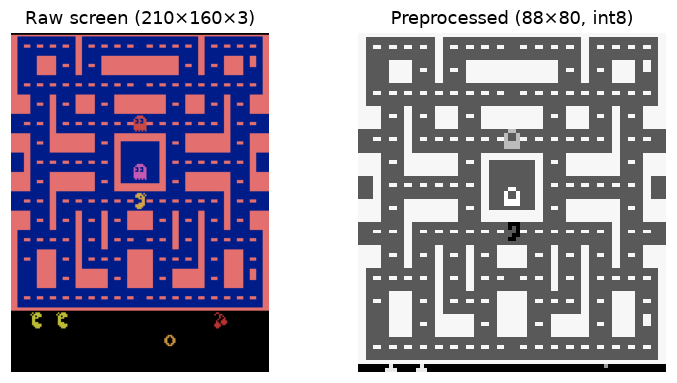

In [5]:
mspacman_color = 210 + 164 + 74

def preprocess_observation(obs):
    img = obs[1:176:2, ::2]                         # crop and downsize
    img = img.sum(axis=2)                           # to greyscale
    img[img == mspacman_color] = 0                  # Improve contrast
    img = (img // 3 - 128).astype(np.int8)          # normalize from -128 to 127
    return img.reshape(88, 80, 1)


def preprocess_safe(obs):
    img = obs[1:176:2, ::2].astype(np.int16).sum(axis=2)
    img[img == mspacman_color] = 0
    return (img // 3 - 128).astype(np.int8)


def preprocess(obs):
    """(210, 160, 3) uint8 screen -> (88, 80) int8"""
    return preprocess_observation(obs)[:, :, 0]


env = gym.make("ALE/MsPacman-v5")
obs, info = env.reset(seed=SEED)
for _ in range(60):
    obs, _, _, _, info = env.step(0)
raw_sum = obs[1:176:2, ::2].astype(np.int16).sum(axis=2)
print("Assignment function == type-safe version:", np.array_equal(preprocess(obs), preprocess_safe(obs)))
print("Output shape", preprocess(obs).shape, "| dtype", preprocess(obs).dtype,
      "| value range", preprocess(obs).min(), "..", preprocess(obs).max())
print("Pixels of Ms. Pac-Man's colour in this screen:", int((raw_sum == mspacman_color).sum()), "(these are set to black)")
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(obs); axes[0].set_title("Raw screen (210×160×3)")
axes[1].imshow(preprocess(obs), cmap="gray"); axes[1].set_title("Preprocessed (88×80, int8)")
for ax in axes:
    ax.axis("off"); ax.grid(False)
fig.savefig(os.path.join(RUN_DIR, "preprocessing.png"), dpi=150, bbox_inches="tight")
plt.show()

### Check 2: environment settings

In [6]:
spec = env.spec
print("env id:", spec.id, "| kwargs:", {k: v for k, v in spec.kwargs.items() if k in ("frameskip", "repeat_action_probability", "full_action_space", "obs_type")})
ACTION_NAMES = list(env.unwrapped.get_action_meanings())
print("actions:", env.action_space.n, ACTION_NAMES)
print("info at reset:", {k: info[k] for k in info if k in ("lives", "frame_number", "episode_frame_number")})
assert env.action_space.n == N_ACTIONS, "the assignment says 9 actions"
env.close()

env id: ALE/MsPacman-v5 | kwargs: {'repeat_action_probability': 0.25, 'full_action_space': False, 'frameskip': 4}
actions: 9 ['NOOP', 'UP', 'RIGHT', 'LEFT', 'DOWN', 'UPRIGHT', 'UPLEFT', 'DOWNRIGHT', 'DOWNLEFT']
info at reset: {'lives': 3, 'episode_frame_number': 240, 'frame_number': 240}


### Check 3: random play baseline

In [7]:
def random_play(n=10, seed=123):
    env = gym.make("ALE/MsPacman-v5"); rng = np.random.default_rng(seed)
    scores, lengths = [], []
    for ep in range(n):
        env.reset(seed=seed + ep); total, steps, done = 0.0, 0, False
        while not done:
            _, r, term, trunc, _ = env.step(int(rng.integers(N_ACTIONS))); total += r; steps += 1; done = term or trunc
        scores.append(total); lengths.append(steps)
    env.close()
    return np.array(scores), np.array(lengths)


random_scores, random_lengths = random_play(10)
print(f"random play, 10 games: score mean {random_scores.mean():.0f} ± {random_scores.std():.0f} | steps per game mean {random_lengths.mean():.0f}")

random play, 10 games: score mean 264 ± 136 | steps per game mean 499


## Replay buffer

Each preprocessed frame is stored once (int8) and 4-frame stacks are rebuilt when sampling. Frames older than a done flag are zeroed; the newest frame and frames whose history was overwritten are not sampled.

In [8]:
class FrameReplay:
    def __init__(self, capacity, k=FRAME_STACK, h=H, w=W):
        self.frames = np.zeros((capacity, h, w), np.int8)
        self.actions = np.zeros(capacity, np.int64)
        self.rewards = np.zeros(capacity, np.float32)
        self.dones = np.zeros(capacity, np.bool_)
        self.cap, self.k, self.ptr, self.size = capacity, k, 0, 0

    def add(self, frame, action, reward, done):
        i = self.ptr
        self.frames[i], self.actions[i], self.rewards[i], self.dones[i] = frame, action, reward, done
        self.ptr = (i + 1) % self.cap
        self.size = min(self.size + 1, self.cap)

    def __len__(self):
        return self.size

    def _valid(self, i):
        newest = (self.ptr - 1) % self.cap
        ok = i != newest                                               # needs a successor screen
        if self.size == self.cap:                                      # history of the k-1 screens after ptr is overwritten
            ok &= ((i - self.ptr) % self.cap) >= self.k - 1
        return ok

    def stacks(self, idx):
        """(B,) indices of the newest screen -> (B, k, h, w) int8 stacks, zeroed before any done inside the window."""
        offs = np.arange(self.k - 1, -1, -1)
        fi = (np.asarray(idx)[:, None] - offs[None, :]) % self.cap     # oldest ... newest
        out = self.frames[fi]                                           # fancy indexing copies
        d = self.dones[fi[:, :-1]]                                      # done flags of the k-1 older screens
        cut = np.flip(np.cumsum(np.flip(d, 1), 1), 1) > 0               # True at a done screen and everything older
        out[:, :-1][cut] = 0
        return out

    def sample(self, batch_size, rng):
        idx = np.empty(batch_size, np.int64); n = 0
        while n < batch_size:
            cand = rng.integers(0, self.size, size=batch_size - n)
            ok = self._valid(cand); m = int(ok.sum())
            idx[n:n + m] = cand[ok]; n += m
        return (self.stacks(idx), self.actions[idx], self.rewards[idx],
                self.stacks((idx + 1) % self.cap), self.dones[idx].astype(np.float32))

    def save(self, path):
        np.savez(path, frames=self.frames, actions=self.actions, rewards=self.rewards, dones=self.dones,
                 ptr=self.ptr, size=self.size)

    def load(self, path):
        z = np.load(path)
        if z["frames"].shape != self.frames.shape:
            print("buffer file has a different capacity; starting with an empty buffer"); return False
        self.frames[:], self.actions[:], self.rewards[:], self.dones[:] = z["frames"], z["actions"], z["rewards"], z["dones"]
        self.ptr, self.size = int(z["ptr"]), int(z["size"])
        return True


class LiveStack:
    """The agent's own 4-screen window, kept identical to what the buffer rebuilds."""
    def __init__(self, k=FRAME_STACK, h=H, w=W):
        self.frames = np.zeros((k, h, w), np.int8)

    def reset(self, frame):
        self.frames[:] = 0; self.frames[-1] = frame
        return self.frames

    def push(self, frame):
        self.frames = np.roll(self.frames, -1, axis=0); self.frames[-1] = frame
        return self.frames

### Check 4: replay buffer

Synthetic frames stamped with their time step: every rebuilt stack must equal the stack the agent saw.

In [9]:
def check_frame_replay(cap, n_add, k=4, seed=0):
    rng = np.random.default_rng(seed)
    buf = FrameReplay(cap, k=k, h=2, w=2)
    live = LiveStack(k=k, h=2, w=2)
    live_stacks, t = [], 0                                   # live_stacks[t] = the window the agent saw at time t
    while t < n_add:
        length = int(rng.integers(1, 9))                     # a "game" of 1-8 screens
        for j in range(length):
            if t >= n_add:
                break
            frame = np.full((2, 2), t % 127, np.int8)        # pixel value = time stamp
            stack = live.reset(frame) if j == 0 else live.push(frame)
            live_stacks.append(stack.copy())
            buf.add(frame, t % 7, float(t), j == length - 1)
            t += 1
    newest = (buf.ptr - 1) % cap
    n_checked = 0
    for i in range(buf.size):
        if not buf._valid(np.array([i]))[0]:
            continue
        t_i = n_add - 1 - ((newest - i) % cap)              # absolute time of the screen stored in slot i
        s = buf.stacks(np.array([i]))[0]
        s2 = buf.stacks(np.array([(i + 1) % cap]))[0]
        assert np.array_equal(s, live_stacks[t_i]), f"stack rebuilt for time {t_i} differs from what the agent saw"
        assert np.array_equal(s2, live_stacks[t_i + 1]), f"next-stack rebuilt for time {t_i} differs from what the agent saw"
        assert buf.rewards[i] == float(t_i) and buf.actions[i] == t_i % 7, "action/reward misaligned with the screen"
        n_checked += 1
    for _ in range(50):                                      # random batches: s2 follows s
        s, a, r, s2, d = buf.sample(16, rng)
        assert np.all((s2[:, -1, 0, 0].astype(int) - s[:, -1, 0, 0].astype(int)) % 127 == 1)
        assert np.all(r.astype(int) % 127 == s[:, -1, 0, 0].astype(int))
    n_invalid = buf.size - n_checked
    print(f"capacity {cap}, {n_add} screens added: {n_checked} valid slots rebuild s, s', action and reward exactly as the agent "
          f"saw them; {n_invalid} slot(s) correctly excluded (newest screen{' + overwritten history' if n_add > cap else ''})")


check_frame_replay(cap=50, n_add=130)     # wrap-around happens
check_frame_replay(cap=200, n_add=130)    # buffer not yet full

capacity 50, 130 screens added: 46 valid slots rebuild s, s', action and reward exactly as the agent saw them; 4 slot(s) correctly excluded (newest screen + overwritten history)
capacity 200, 130 screens added: 129 valid slots rebuild s, s', action and reward exactly as the agent saw them; 1 slot(s) correctly excluded (newest screen)


## Q-network (Nature DQN, 88x80 input)

In [10]:
class AtariQNet(nn.Module):
    def __init__(self, in_frames=FRAME_STACK, n_actions=N_ACTIONS, h=H, w=W):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(in_frames, 32, 8, stride=4), nn.ReLU(),
                                  nn.Conv2d(32, 64, 4, stride=2), nn.ReLU(),
                                  nn.Conv2d(64, 64, 3, stride=1), nn.ReLU(), nn.Flatten())
        with torch.no_grad():
            n_flat = self.conv(torch.zeros(1, in_frames, h, w)).shape[1]
        self.head = nn.Sequential(nn.Linear(n_flat, 512), nn.ReLU(), nn.Linear(512, n_actions))

    def forward(self, x):
        return self.head(self.conv(x))


def to_input(stacks_int8):
    """(B, k, h, w) int8 numpy -> float tensor in [-1, 1) on the device"""
    return torch.from_numpy(np.ascontiguousarray(stacks_int8)).to(DEVICE, non_blocking=True).float().div_(128.0)


_net = AtariQNet()
print(_net)
print("parameters:", sum(p.numel() for p in _net.parameters()))
print("output for one stack:", _net(to_input(np.zeros((1, FRAME_STACK, H, W), np.int8)).cpu()).shape)

AtariQNet(
  (conv): Sequential(
    (0): Conv2d(4, 32, kernel_size=(8, 8), stride=(4, 4))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
    (3): ReLU()
    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (head): Sequential(
    (0): Linear(in_features=2688, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=9, bias=True)
  )
)
parameters: 1459369
output for one stack: torch.Size([1, 9])


## Schedules and update

Epsilon is piecewise linear in environment steps; the learning rate decays linearly per episode. Target: y = r + gamma * (1 - done) * max_a Q_target(s', a), Huber loss, gradient clipping.

In [11]:
def epsilon_at(step, schedule=EPS_SCHEDULE):
    s0, e0 = schedule[0]
    for s1, e1 in schedule[1:]:
        if step < s1:
            return e0 + (e1 - e0) * (step - s0) / (s1 - s0)
        s0, e0 = s1, e1
    return e0


def lr_at(episode):
    if not USE_LR_SCHEDULE:
        return LR
    return LR * max(LR_FLOOR, 1.0 - episode / MAX_EPISODES)


def dqn_update(online, target, opt, batch, gamma=GAMMA):
    s, a, r, s2, done = batch
    s, s2 = to_input(s), to_input(s2)
    a = torch.from_numpy(a).to(DEVICE); r = torch.from_numpy(r).to(DEVICE); done = torch.from_numpy(done).to(DEVICE)
    q_sa = online(s).gather(1, a.unsqueeze(1)).squeeze(1)
    with torch.no_grad():
        y = r + gamma * (1.0 - done) * target(s2).max(dim=1).values
    loss = F.smooth_l1_loss(q_sa, y) if HUBER else F.mse_loss(q_sa, y)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    if GRAD_CLIP:
        nn.utils.clip_grad_norm_(online.parameters(), GRAD_CLIP)
    opt.step()
    return loss.item()


def sync_target(online, target):
    target.load_state_dict(online.state_dict())


print("epsilon at 0 / 250k / 500k / 1M / 2M / 5M steps:", [round(epsilon_at(t), 3) for t in (0, 250_000, 500_000, 1_000_000, 2_000_000, 5_000_000)])
print("lr at episode 0 / 2500 / 5000:", [lr_at(e) for e in (0, MAX_EPISODES // 2, MAX_EPISODES)])

epsilon at 0 / 250k / 500k / 1M / 2M / 5M steps: [1.0, 0.55, 0.1, 0.073, 0.02, 0.02]
lr at episode 0 / 2500 / 5000: [0.0001, 5e-05, 2.5e-05]


### Check 5: update sanity check

In [12]:
torch.manual_seed(0)
_on, _tg = AtariQNet().to(DEVICE), AtariQNet().to(DEVICE); sync_target(_on, _tg)
_opt = torch.optim.Adam(_on.parameters(), lr=LR)
_rng = np.random.default_rng(0)
_s = _rng.integers(-128, 128, size=(8, FRAME_STACK, H, W)).astype(np.int8)
_batch = (_s, _rng.integers(0, N_ACTIONS, 8), np.ones(8, np.float32), _s[::-1].copy(), np.ones(8, np.float32))
_before_t = [p.clone() for p in _tg.parameters()]; _before_o = [p.clone() for p in _on.parameters()]
dqn_update(_on, _tg, _opt, _batch)
print("target unchanged:", all(torch.equal(p, q) for p, q in zip(_before_t, _tg.parameters())),
      "| online changed:", any(not torch.equal(p, q) for p, q in zip(_before_o, _on.parameters())))
with torch.no_grad():
    _y = 1.0 + GAMMA * (1 - 1.0) * _tg(to_input(_batch[3])).max(1).values
print("all done -> targets all equal r = 1:", bool(torch.allclose(_y, torch.ones_like(_y))))
del _on, _tg, _opt

target unchanged: True | online changed: True
all done -> targets all equal r = 1: True


## Helpers

In [13]:
def moving_average(x, w=100):
    x = np.asarray(x, dtype=float)
    c = np.concatenate([[0.0], np.cumsum(x)])
    idx = np.arange(len(x)); lo = np.maximum(0, idx - w + 1)
    return (c[idx + 1] - c[lo]) / (idx + 1 - lo)


def plot_history(history, title, save_path=None, random_ref=None):
    r = history["reward"]; ep = np.arange(1, len(r) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    ax = axes[0]
    ax.plot(ep, r, lw=0.6, color=C_BLUE, alpha=0.3, label="Episode score")
    ax.plot(ep, moving_average(r, 100), lw=2, color=C_BLUE, label="Moving average (100 episodes)")
    if random_ref is not None:
        ax.axhline(random_ref, color=C_GRAY, ls="--", lw=1.2, label=f"random play ≈ {random_ref:.0f}")
    ax.set_xlabel("Training episode"); ax.set_ylabel("Episode score (game points)"); ax.set_title(title)
    ax.legend(loc="upper left", frameon=False)
    ax = axes[1]
    ax.plot(ep, history["max_q"], lw=1, color=C_ORANGE, alpha=0.5, label="mean over the episode of max_a Q(s_t, a)")
    if history["heldout_q"]:
        he, hq = zip(*history["heldout_q"])
        ax.plot(he, hq, lw=2, color=C_ORANGE, label=f"max-Q on {HELDOUT_N} fixed held-out states")
    ax.set_xlabel("Training episode"); ax.set_ylabel("Q-value (clipped-reward units)" if REWARD_CLIP else "Q-value")
    ax.set_title("Maximum Q-value versus training episodes"); ax.legend(loc="upper left", frameon=False)
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def save_all(online, target, opt, history, state):
    ck = {"online": online.state_dict(), "target": target.state_dict(), "opt": opt.state_dict(), "state": state,
          "config": {k: globals()[k] for k in ["GAMMA", "FRAME_STACK", "BUFFER_SIZE", "BATCH_SIZE", "WARMUP_STEPS", "TRAIN_EVERY",
                                               "TARGET_SYNC", "LR", "LR_FLOOR", "EPS_SCHEDULE", "REWARD_CLIP", "LIFE_LOSS_TERMINAL", "HUBER"]}}
    torch.save(ck, CKPT_PATH + ".tmp"); os.replace(CKPT_PATH + ".tmp", CKPT_PATH)     # never a half-written checkpoint
    with open(HIST_PATH + ".tmp", "w") as f:
        json.dump(history, f)
    os.replace(HIST_PATH + ".tmp", HIST_PATH)


def status_line(history, state):
    r = history["reward"]
    last100 = np.mean(r[-100:]) if r else float("nan")
    best100 = state["best_ma"]
    hours = state["train_seconds"] / 3600
    sps = state["total_steps"] / max(state["train_seconds"], 1e-9)
    return (f"episodes {len(r)} | steps {state['total_steps']} | updates {state['n_updates']} | last-100 avg {last100:.0f} | "
            f"best-100 avg {best100:.0f} | eps {epsilon_at(state['total_steps']):.3f} | lr {lr_at(len(r)):.2e} | "
            f"{sps:.0f} steps/s | {hours:.2f} h")

## Episode loop

Used for training and evaluation. A lost life ends the bootstrap and resets the frame stack; the score keeps accumulating.

In [14]:
def run_episode(env, online, seed, rng, eps_fn, *, train=False, target=None, opt=None, buffer=None, state=None,
                mask_history=False, record_trace=False):
    obs, info = env.reset(seed=seed)
    frame = preprocess(obs); live = LiveStack(); stack = live.reset(frame)
    lives = info.get("lives", 0)
    score, steps, maxqs, losses, trace = 0.0, 0, [], [], []
    while True:
        eps = eps_fn(state["total_steps"]) if train else eps_fn(0)
        x = stack.copy()
        if mask_history:
            x[:-1] = 0                                       # ablation: current frame only
        with torch.no_grad():
            q = online(to_input(x[None]))[0].cpu().numpy()
        maxqs.append(float(q.max()))
        a = int(rng.integers(N_ACTIONS)) if rng.random() < eps else int(q.argmax())
        obs, r, terminated, truncated, info = env.step(a)
        score += r; steps += 1
        life_lost = info.get("lives", lives) < lives; lives = info.get("lives", lives)
        if record_trace:
            trace.append((q, a, r, life_lost))
        done_for_target = terminated or truncated or (LIFE_LOSS_TERMINAL and life_lost)
        if train:
            buffer.add(frame, a, np.sign(r) if REWARD_CLIP else r, done_for_target)
            state["total_steps"] += 1
            if len(buffer) >= WARMUP_STEPS and state["total_steps"] % TRAIN_EVERY == 0:
                losses.append(dqn_update(online, target, opt, buffer.sample(BATCH_SIZE, rng)))
                state["n_updates"] += 1
            if state["total_steps"] % TARGET_SYNC == 0:
                sync_target(online, target)
        frame = preprocess(obs)
        stack = live.reset(frame) if (done_for_target and not (terminated or truncated)) else live.push(frame)
        if terminated or truncated:
            break
    out = {"score": score, "steps": steps, "max_q": float(np.mean(maxqs)), "peak_q": float(np.max(maxqs)),
           "loss": float(np.mean(losses)) if losses else float("nan")}
    if record_trace:
        out["trace"] = trace
    return out

### Smoke test and time estimate

In [15]:
_env = gym.make("ALE/MsPacman-v5"); _rng = np.random.default_rng(1)
_on, _tg = AtariQNet().to(DEVICE), AtariQNet().to(DEVICE); sync_target(_on, _tg)
_opt = torch.optim.Adam(_on.parameters(), lr=LR)
_buf = FrameReplay(5_000); _state = {"total_steps": 0, "n_updates": 0}
_warm = WARMUP_STEPS; WARMUP_STEPS = 200
t0 = time.time(); _res = [run_episode(_env, _on, 1000 + i, _rng, epsilon_at, train=True, target=_tg, opt=_opt, buffer=_buf, state=_state) for i in range(3)]
secs = time.time() - t0; WARMUP_STEPS = _warm; _env.close()
sps = _state["total_steps"] / secs
est_steps = MAX_EPISODES * max(random_lengths.mean(), 1)
print(f"3 games: scores {[r['score'] for r in _res]}, {_state['total_steps']} steps, {_state['n_updates']} updates, {sps:.0f} steps/s (with learning)")
print(f"Estimate for {MAX_EPISODES} games of ≈{random_lengths.mean():.0f} steps: {est_steps / sps / 3600:.1f} hours "
      f"(games get longer as the agent improves, so expect more; TRAIN_HOURS = {TRAIN_HOURS} caps it)")
del _on, _tg, _opt, _buf

3 games: scores [220.0, 200.0, 230.0], 1435 steps, 309 updates, 294 steps/s (with learning)
Estimate for 5000 games of ≈499 steps: 2.4 hours (games get longer as the agent improves, so expect more; TRAIN_HOURS = 20 caps it)


## Training

In [16]:
if RUN_TRAINING:
    torch.manual_seed(SEED); np.random.seed(SEED)
    rng = np.random.default_rng(SEED)
    online, target = AtariQNet().to(DEVICE), AtariQNet().to(DEVICE); sync_target(online, target)
    opt = torch.optim.Adam(online.parameters(), lr=LR, eps=1.5e-4)
    buffer = FrameReplay(BUFFER_SIZE)
    history = {"reward": [], "length": [], "max_q": [], "peak_q": [], "loss": [], "eps": [], "lr": [], "steps_at_end": [], "heldout_q": []}
    state = {"total_steps": 0, "n_updates": 0, "train_seconds": 0.0, "best_ma": -1.0}
    heldout = None

    if os.path.exists(CKPT_PATH):
        ck = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)
        online.load_state_dict(ck["online"]); target.load_state_dict(ck["target"]); opt.load_state_dict(ck["opt"])
        state = ck["state"]
        with open(HIST_PATH) as f:
            history = json.load(f)
        if os.path.exists(BUFFER_PATH) and buffer.load(BUFFER_PATH):
            print(f"replay buffer restored: {len(buffer)} screens")
        else:
            print("no saved replay buffer: it refills from play before learning restarts (needs WARMUP_STEPS screens)")
        if os.path.exists(HELDOUT_PATH):
            heldout = np.load(HELDOUT_PATH)
        rng = np.random.default_rng(SEED + len(history["reward"]))
        print(f"Resumed: {len(history['reward'])} episodes, {state['total_steps']} steps, {state['n_updates']} updates, {state['train_seconds'] / 3600:.2f} h")

    env = gym.make("ALE/MsPacman-v5")
    session_start, seconds_before = time.time(), state["train_seconds"]
    if os.path.exists(STOP_PATH):
        os.remove(STOP_PATH)

    try:
        while len(history["reward"]) < MAX_EPISODES and (time.time() - session_start) < TRAIN_HOURS * 3600:
            ep = len(history["reward"]) + 1
            for g in opt.param_groups:
                g["lr"] = lr_at(ep)
            res = run_episode(env, online, SEED * 100_000 + ep, rng, epsilon_at, train=True, target=target, opt=opt, buffer=buffer, state=state)
            history["reward"].append(res["score"]); history["length"].append(res["steps"])
            history["max_q"].append(res["max_q"]); history["peak_q"].append(res["peak_q"]); history["loss"].append(res["loss"])
            history["eps"].append(epsilon_at(state["total_steps"])); history["lr"].append(lr_at(ep)); history["steps_at_end"].append(state["total_steps"])
            state["train_seconds"] = seconds_before + (time.time() - session_start)

            if heldout is None and len(buffer) >= WARMUP_STEPS:             # held-out states from early random play
                heldout = buffer.sample(HELDOUT_N, rng)[0]; np.save(HELDOUT_PATH, heldout)
            if heldout is not None and ep % HELDOUT_EVERY == 0:
                with torch.no_grad():
                    hq = float(np.mean([online(to_input(heldout[i:i + 64])).max(1).values.mean().item() for i in range(0, HELDOUT_N, 64)]))
                history["heldout_q"].append([ep, hq])

            ma = float(np.mean(history["reward"][-100:]))
            if ep >= 100 and ma > state["best_ma"]:
                state["best_ma"] = ma; torch.save(online.state_dict(), BEST_PATH)
            if ep % SAVE_EVERY == 0:
                save_all(online, target, opt, history, state)
                with open(LOG_PATH, "a") as f:
                    f.write(status_line(history, state) + "\n")
            if ep % PLOT_EVERY == 0:
                clear_output(wait=True)
                plot_history(history, f"MsPacman-v5 DQN, run {RUN_NAME} (live)", random_ref=random_scores.mean())
                print(status_line(history, state))
            if os.path.exists(STOP_PATH):
                print("STOP file found: stopping after this episode."); os.remove(STOP_PATH); break
    except KeyboardInterrupt:
        print("Stopped by you.")
    finally:
        state["train_seconds"] = seconds_before + (time.time() - session_start)
        save_all(online, target, opt, history, state)
        try:
            buffer.save(BUFFER_PATH)                   # ~1.4 GB, resume without warm-up
        except Exception as exc:
            print("replay buffer not saved:", exc)
        env.close()
        print("Saved.", status_line(history, state))

## Plots (i) and (ii)

Left: episode score with 100-episode moving average. Right: max-Q along the agent's play and on 256 fixed held-out frames.

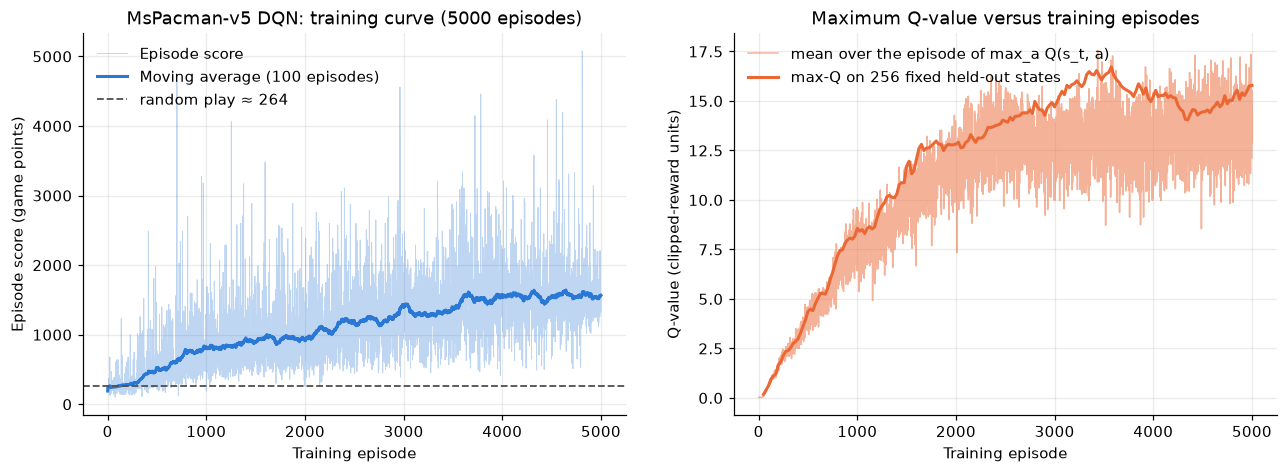

episodes 5000 | first-100 avg 260 | last-100 avg 1566 | best 100-avg 1642 | random play 264


In [17]:
if RUN_AFTER_TRAINING:
    with open(HIST_PATH) as f:
        history = json.load(f)
    plot_history(history, f"MsPacman-v5 DQN: training curve ({len(history['reward'])} episodes)",
                 save_path=os.path.join(RUN_DIR, "training_curves.png"), random_ref=random_scores.mean())
    r = np.array(history["reward"]); ma = moving_average(r)
    print(f"episodes {len(r)} | first-100 avg {r[:100].mean():.0f} | last-100 avg {r[-100:].mean():.0f} | best 100-avg {ma[99:].max() if len(r) >= 100 else float('nan'):.0f} "
          f"| random play {random_scores.mean():.0f}")

## Plot (iii): 500 evaluation games

epsilon = 0.01 during evaluation.

  50/500 games (1.0 min) | running mean 1729
  100/500 games (1.9 min) | running mean 1733
  150/500 games (2.8 min) | running mean 1710
  200/500 games (3.7 min) | running mean 1720
  250/500 games (4.7 min) | running mean 1739
  300/500 games (5.7 min) | running mean 1732
  350/500 games (6.6 min) | running mean 1714
  400/500 games (7.6 min) | running mean 1722
  450/500 games (8.5 min) | running mean 1725
  500/500 games (9.5 min) | running mean 1720

500 games | mean 1720.0 | std 364.5 | min 890 | max 3440 | random play 264


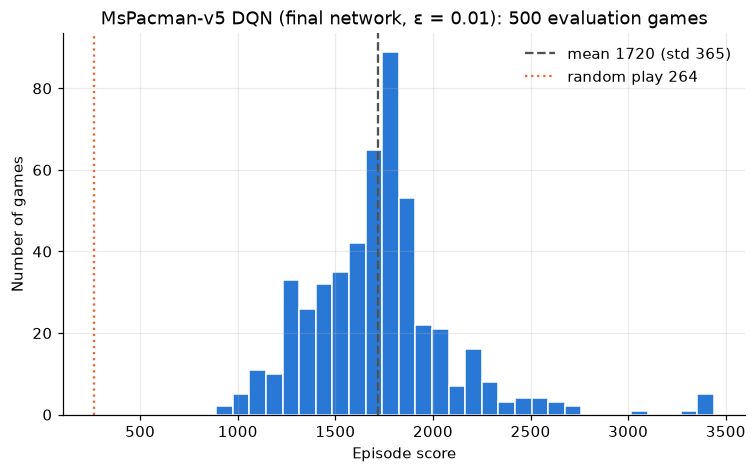

In [18]:
EVAL_WHICH = "final"           # "final" or "best"

def load_net(which="final"):
    net = AtariQNet().to(DEVICE)
    if which == "best" and os.path.exists(BEST_PATH):
        net.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE, weights_only=False))
    else:
        net.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)["online"])
    net.eval()
    return net


def evaluate(net, n=EVAL_EPISODES, eps=EVAL_EPS, seed=12345, mask_history=False, verbose=True):
    env = gym.make("ALE/MsPacman-v5"); rng = np.random.default_rng(seed)
    scores, lengths, t0 = [], [], time.time()
    for i in range(n):
        res = run_episode(env, net, seed + i, rng, lambda step: eps, mask_history=mask_history)
        scores.append(res["score"]); lengths.append(res["steps"])
        if verbose and (i + 1) % 50 == 0:
            print(f"  {i + 1}/{n} games ({(time.time() - t0) / 60:.1f} min) | running mean {np.mean(scores):.0f}")
    env.close()
    return np.array(scores), np.array(lengths)


if RUN_AFTER_TRAINING:
    eval_net = load_net(EVAL_WHICH)
    eval_scores, eval_lengths = evaluate(eval_net)
    mean, std = eval_scores.mean(), eval_scores.std()
    print(f"\n{len(eval_scores)} games | mean {mean:.1f} | std {std:.1f} | min {eval_scores.min():.0f} | max {eval_scores.max():.0f} | random play {random_scores.mean():.0f}")
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(eval_scores, bins=30, color=C_BLUE, edgecolor="white", linewidth=1)
    ax.axvline(mean, color=C_GRAY, lw=1.5, ls="--", label=f"mean {mean:.0f} (std {std:.0f})")
    ax.axvline(random_scores.mean(), color=C_ORANGE, lw=1.5, ls=":", label=f"random play {random_scores.mean():.0f}")
    ax.set_xlabel("Episode score"); ax.set_ylabel("Number of games")
    ax.set_title(f"MsPacman-v5 DQN ({EVAL_WHICH} network, ε = {EVAL_EPS}): {len(eval_scores)} evaluation games")
    ax.legend(frameon=False)
    fig.savefig(os.path.join(RUN_DIR, f"eval_histogram_{EVAL_WHICH}.png"), dpi=150, bbox_inches="tight")
    plt.show()
    with open(os.path.join(RUN_DIR, f"eval_{EVAL_WHICH}.json"), "w") as f:
        json.dump({"scores": eval_scores.tolist(), "lengths": eval_lengths.tolist(), "mean": float(mean), "std": float(std), "eps": EVAL_EPS}, f)

# Validation tests

- A: trained vs. random play, 20 games each.
- B: the 3 older frames zeroed at play time (motion removed).
- C: evaluation epsilon 0 / 0.01 / 0.05.
- D: predicted Q vs. realized clipped return per life.

In [19]:
if RUN_AFTER_TRAINING:
    n_test = 20
    tA, _ = evaluate(eval_net, n=n_test, seed=777, verbose=False)
    rnd, _ = random_play(n_test, seed=777)
    se = np.sqrt(tA.var() / n_test + rnd.var() / n_test)
    print(f"A. trained {tA.mean():.0f} ± {tA.std():.0f} vs random {rnd.mean():.0f} ± {rnd.std():.0f} | gap {tA.mean() - rnd.mean():.0f} = {(tA.mean() - rnd.mean()) / se:.1f} standard errors")
    tB, _ = evaluate(eval_net, n=n_test, seed=777, mask_history=True, verbose=False)
    print(f"B. motion hidden: {tB.mean():.0f} ± {tB.std():.0f}  vs with motion {tA.mean():.0f}  (drop of {100 * (1 - tB.mean() / max(tA.mean(), 1)):.0f} %)")
    for e in (0.0, 0.01, 0.05):
        sc, ln = evaluate(eval_net, n=n_test, eps=e, seed=777, verbose=False)
        print(f"C. eps = {e:<4}: score {sc.mean():6.0f} ± {sc.std():5.0f} | game length mean {ln.mean():6.0f}, max {ln.max():6.0f}")

A. trained 1696 ± 296 vs random 281 ± 147 | gap 1416 = 19.2 standard errors
B. motion hidden: 286 ± 108  vs with motion 1696  (drop of 83 %)
C. eps = 0.0 : score   1684 ±   343 | game length mean    764, max   1325
C. eps = 0.01: score   1696 ±   296 | game length mean    751, max   1009
C. eps = 0.05: score   1538 ±   329 | game length mean    778, max   1519


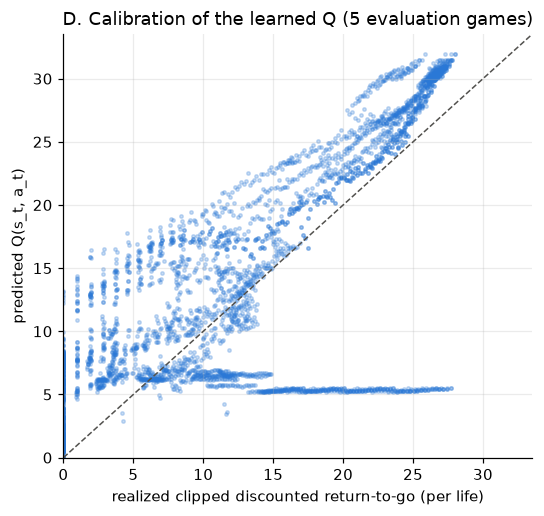

D. 3807 steps | mean |Q − G| = 5.09 | correlation 0.759 | mean Q 14.22 | mean G 12.42


In [20]:
def discounted_returns(rewards, gamma):
    G = np.zeros(len(rewards), dtype=np.float32); running = 0.0
    for t in reversed(range(len(rewards))):
        running = rewards[t] + gamma * running; G[t] = running
    return G


if RUN_AFTER_TRAINING:
    env = gym.make("ALE/MsPacman-v5"); rng = np.random.default_rng(4242)
    pred, real = [], []
    for i in range(5):
        res = run_episode(env, eval_net, 4242 + i, rng, lambda step: EVAL_EPS, record_trace=True)
        qs = [q[a] for q, a, r, ll in res["trace"]]
        rs = [np.sign(r) if REWARD_CLIP else r for q, a, r, ll in res["trace"]]
        # returns per life, as in the targets
        seg_start = 0
        for t, (q, a, r, ll) in enumerate(res["trace"]):
            if ll or t == len(res["trace"]) - 1:
                real += list(discounted_returns(rs[seg_start:t + 1], GAMMA)); seg_start = t + 1
        pred += qs
    env.close()
    pred, real = np.array(pred), np.array(real)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.scatter(real, pred, s=5, alpha=0.25, color=C_BLUE)
    lim = max(real.max(), pred.max()) * 1.05
    ax.plot([0, lim], [0, lim], color=C_GRAY, ls="--", lw=1); ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_xlabel("realized clipped discounted return-to-go (per life)"); ax.set_ylabel("predicted Q(s_t, a_t)")
    ax.set_title("D. Calibration of the learned Q (5 evaluation games)")
    fig.savefig(os.path.join(RUN_DIR, "calibration.png"), dpi=150, bbox_inches="tight"); plt.show()
    print(f"D. {len(pred)} steps | mean |Q − G| = {np.abs(pred - real).mean():.2f} | correlation {np.corrcoef(pred, real)[0, 1]:.3f} | mean Q {pred.mean():.2f} | mean G {real.mean():.2f}")

# Non-standard plots

Saliency |d max Q / d pixels| at four moments of one game, and all 9 Q-values along one full game (Q-value oscilloscope).

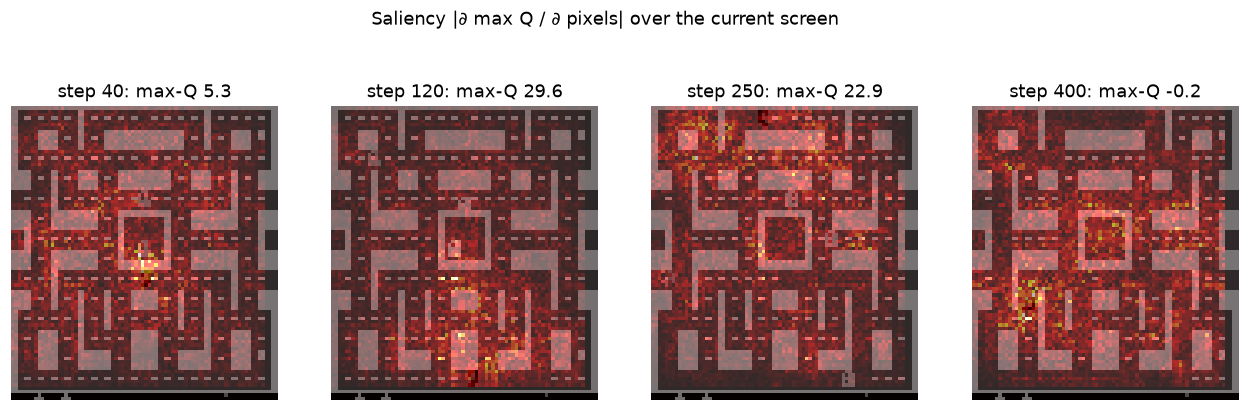

In [21]:
if RUN_AFTER_TRAINING:
    env = gym.make("ALE/MsPacman-v5"); rng = np.random.default_rng(99)
    obs, info = env.reset(seed=99); frame = preprocess(obs); live = LiveStack(); stack = live.reset(frame); lives = info.get("lives", 0)
    snapshots, t = [], 0
    while True:
        x = to_input(stack[None]).requires_grad_(True)
        q = eval_net(x); a = int(q[0].argmax())
        if t in (40, 120, 250, 400):
            eval_net.zero_grad(set_to_none=True); q[0].max().backward()
            snapshots.append((t, stack[-1].copy(), x.grad[0].abs().sum(0).cpu().numpy(), q[0].detach().cpu().numpy()))
        obs, r, term, trunc, info = env.step(a if rng.random() >= EVAL_EPS else int(rng.integers(N_ACTIONS)))
        life_lost = info.get("lives", lives) < lives; lives = info.get("lives", lives)
        frame = preprocess(obs); stack = live.reset(frame) if (life_lost and not (term or trunc)) else live.push(frame); t += 1
        if term or trunc or len(snapshots) == 4:
            break
    env.close()
    fig, axes = plt.subplots(1, len(snapshots), figsize=(3.6 * len(snapshots), 4.2), squeeze=False)
    for ax, (t, scr, sal, qv) in zip(axes[0], snapshots):
        ax.imshow(scr, cmap="gray"); ax.imshow(sal / (sal.max() + 1e-9), cmap="hot", alpha=0.55)
        ax.set_title(f"step {t}: max-Q {qv.max():.1f}"); ax.axis("off"); ax.grid(False)
    fig.suptitle("Saliency |∂ max Q / ∂ pixels| over the current screen", y=1.02)
    fig.savefig(os.path.join(RUN_DIR, "saliency.png"), dpi=150, bbox_inches="tight"); plt.show()

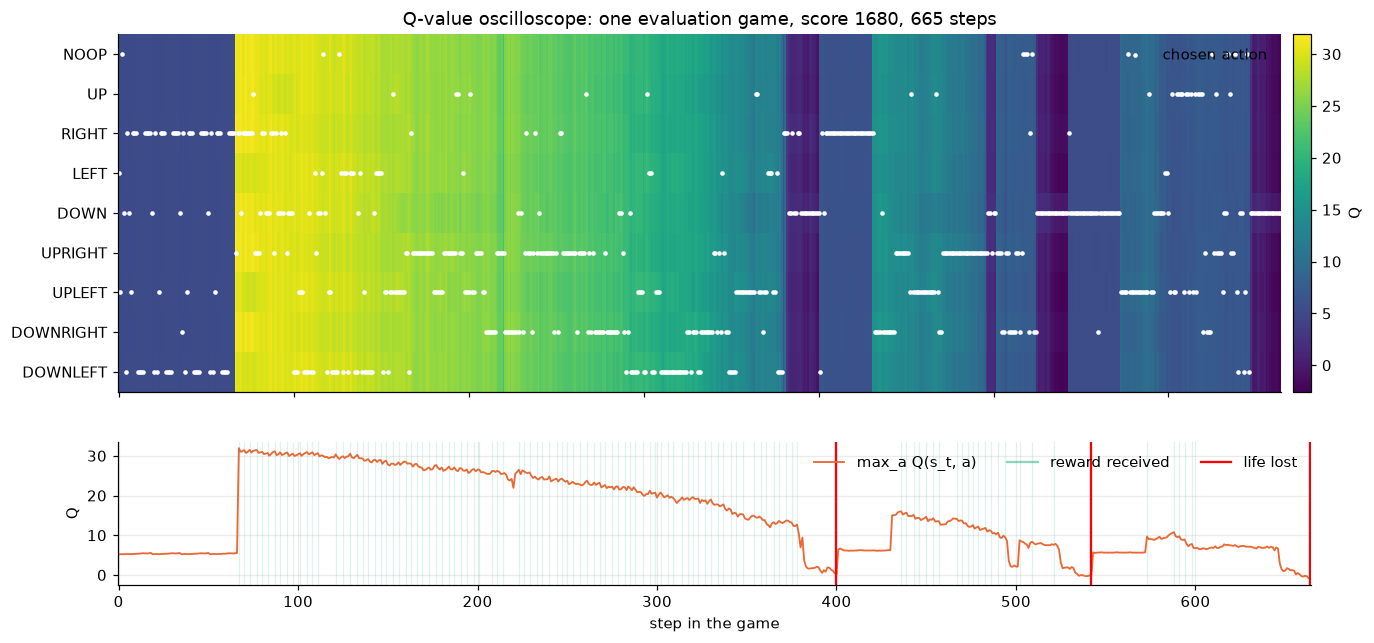

In [22]:
if RUN_AFTER_TRAINING:
    env = gym.make("ALE/MsPacman-v5"); rng = np.random.default_rng(7)
    res = run_episode(env, eval_net, 7, rng, lambda step: EVAL_EPS, record_trace=True); env.close()
    Q = np.array([q for q, a, r, ll in res["trace"]]); A = np.array([a for q, a, r, ll in res["trace"]])
    R = np.array([r for q, a, r, ll in res["trace"]]); L = np.array([ll for q, a, r, ll in res["trace"]])
    names = ACTION_NAMES
    T = len(Q)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
    im = ax1.imshow(Q.T, aspect="auto", cmap="viridis", interpolation="nearest")
    ax1.scatter(np.arange(T), A, s=4, color="white", label="chosen action")
    ax1.set_yticks(range(N_ACTIONS)); ax1.set_yticklabels(names); ax1.grid(False); ax1.legend(loc="upper right", frameon=False)
    ax1.set_title(f"Q-value oscilloscope: one evaluation game, score {res['score']:.0f}, {T} steps")
    fig.colorbar(im, ax=ax1, fraction=0.015, pad=0.01, label="Q")
    ax2.plot(Q.max(1), color=C_ORANGE, lw=1.2, label="max_a Q(s_t, a)")
    for t in np.flatnonzero(R > 0):
        ax2.axvline(t, color=C_AQUA, alpha=0.15, lw=0.8)
    for t in np.flatnonzero(L):
        ax2.axvline(t, color="red", lw=1.5)
    ax2.plot([], [], color=C_AQUA, alpha=0.5, label="reward received"); ax2.plot([], [], color="red", label="life lost")
    ax2.set_xlabel("step in the game"); ax2.set_ylabel("Q"); ax2.legend(loc="upper right", frameon=False, ncol=3)
    fig.savefig(os.path.join(RUN_DIR, "q_oscilloscope.png"), dpi=150, bbox_inches="tight"); plt.show()